# Kepler Exoplanet Project — Beginner Level

## Goal

Build a **beginner-friendly binary classification model** using the NASA/Kepler Objects of Interest (KOI) tabular dataset.

> **Important framing:** this notebook does **not yet detect exoplanets directly from raw light curves**. It learns to classify existing Kepler Objects of Interest as **CONFIRMED** or **FALSE POSITIVE** using already-derived astrophysical measurements.

This is intentional. It lets us learn the complete beginner ML workflow correctly before moving to time-series/light-curve detection.

### What this notebook covers

1. Problem definition
2. Loading and understanding data
3. Data cleaning
4. Univariate and bivariate EDA
5. Physics-based feature engineering
6. Train/test split
7. Scaling
8. Majority-class baseline
9. Logistic Regression
10. Evaluation
11. Basic physics interpretation

### What we will add later

- Cross-validation
- Tree models / XGBoost
- Hyperparameter tuning
- Feature selection / PCA
- SHAP
- Raw Kepler light curves
- Period detection and phase folding
- CNNs
- Uncertainty quantification
- Deployment


## 1. Imports and Environment

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

RANDOM_STATE = 42
DATA_PATH = "cumulative.csv"


## 2. Understand the Problem

We are using the Kepler Objects of Interest table.

### Target

`koi_disposition`

- `CONFIRMED` → 1
- `FALSE POSITIVE` → 0

We intentionally remove `CANDIDATE` and `NOT DISPOSITIONED` for this first binary-classification exercise.

### Important scientific limitation

The columns we use are **already-derived Kepler pipeline / catalog measurements**. For example, NASA defines `koi_depth` as transit depth and `koi_duration` as observed transit duration, while `koi_model_snr` is a transit signal-to-noise measure. 

Therefore, the honest project statement at this stage is:

> **“Classify Kepler Objects of Interest using catalog-level astrophysical features.”**




## 3. Load the Dataset and Inspect It

In [7]:
df = pd.read_csv("cumulative.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (9564, 50)


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [9]:
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget values:")
display(df["koi_disposition"].value_counts(dropna=False))



Column names:
['rowid', 'kepid', 'kepoi_name', 'kepler_name', 'koi_disposition', 'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_tce_delivname', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'ra', 'dec', 'koi_kepmag']

Data types:


rowid                  int64
kepid                  int64
kepoi_name            object
kepler_name           object
koi_disposition       object
koi_pdisposition      object
koi_score            float64
koi_fpflag_nt          int64
koi_fpflag_ss          int64
koi_fpflag_co          int64
koi_fpflag_ec          int64
koi_period           float64
koi_period_err1      float64
koi_period_err2      float64
koi_time0bk          float64
koi_time0bk_err1     float64
koi_time0bk_err2     float64
koi_impact           float64
koi_impact_err1      float64
koi_impact_err2      float64
koi_duration         float64
koi_duration_err1    float64
koi_duration_err2    float64
koi_depth            float64
koi_depth_err1       float64
koi_depth_err2       float64
koi_prad             float64
koi_prad_err1        float64
koi_prad_err2        float64
koi_teq              float64
koi_teq_err1         float64
koi_teq_err2         float64
koi_insol            float64
koi_insol_err1       float64
koi_insol_err2


Duplicate rows: 0

Target values:


koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64

## 4. Select the Beginner Feature Set

We start with a small set of features that have clear physical meaning.

| Feature | Meaning | Unit |
|---|---|---|
| `koi_period` | orbital/transit period | days |
| `koi_duration` | transit duration | hours |
| `koi_depth` | transit depth | ppm |
| `koi_model_snr` | transit model signal-to-noise | dimensionless |
| `koi_steff` | stellar effective temperature | K |
| `koi_slogg` | stellar surface gravity | log(cgs) |
| `koi_srad` | stellar radius | Solar radii |

NASA's column documentation defines these quantities and notes that `koi_depth` and `koi_duration` are derived from transit-model fits to the Kepler light curves. 




In [11]:
target_mapping = {
    "CONFIRMED": 1,
    "FALSE POSITIVE": 0
}

features = [
    "koi_period",
    "koi_duration",
    "koi_depth",
    "koi_model_snr",
    "koi_steff",
    "koi_slogg",
    "koi_srad"
]

df_clean = df[df["koi_disposition"].isin(target_mapping)].copy()
df_clean["LABEL"] = df_clean["koi_disposition"].map(target_mapping)

print("Rows after target filtering:", len(df_clean))
print("\nClass distribution:")
display(df_clean["LABEL"].value_counts().rename(index={0: "FALSE POSITIVE", 1: "CONFIRMED"}))

print("\nMissing values in selected features:")
display(df_clean[features].isna().sum())


Rows after target filtering: 7316

Class distribution:


LABEL
FALSE POSITIVE    5023
CONFIRMED         2293
Name: count, dtype: int64


Missing values in selected features:


koi_period         0
koi_duration       0
koi_depth        300
koi_model_snr    300
koi_steff        300
koi_slogg        300
koi_srad         300
dtype: int64

## 5. Data Cleaning

For this first notebook, we use a simple and transparent rule:

- remove rows with missing values in the selected features;
- keep the original physical units for EDA;
- perform scaling only **after** the train/test split.

This is easy to understand and avoids fitting preprocessing steps on the test set.


In [13]:
before = len(df_clean)

df_clean = df_clean.dropna(subset=features).copy()

after = len(df_clean)

print(f"Rows before dropping missing values: {before}")
print(f"Rows after dropping missing values:  {after}")
print(f"Rows removed:                       {before - after}")

print("\nFinal missing values:")
display(df_clean[features + ["LABEL"]].isna().sum())


Rows before dropping missing values: 7316
Rows after dropping missing values:  7016
Rows removed:                       300

Final missing values:


koi_period       0
koi_duration     0
koi_depth        0
koi_model_snr    0
koi_steff        0
koi_slogg        0
koi_srad         0
LABEL            0
dtype: int64

# 6. Exploratory Data Analysis (EDA)

We will answer four beginner questions:

1. Are the classes balanced?
2. What do individual feature distributions look like?
3. Are there obvious outliers?
4. Which features show relationships with the target or with each other?

**Do not treat EDA as decoration.** Each plot should help us make a decision about the data or model.


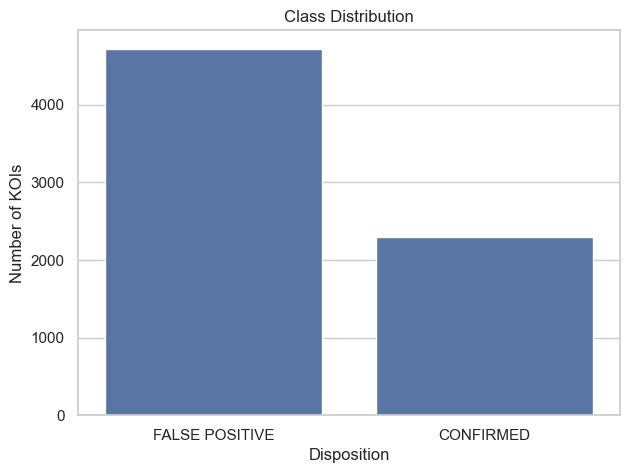

Class proportions:


LABEL
FALSE POSITIVE    0.673318
CONFIRMED         0.326682
Name: proportion, dtype: float64

In [15]:
# 6.1 Class balance
class_counts = df_clean["LABEL"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=["FALSE POSITIVE", "CONFIRMED"],
    y=[class_counts.get(0, 0), class_counts.get(1, 0)]
)
plt.title("Class Distribution")
plt.ylabel("Number of KOIs")
plt.xlabel("Disposition")
plt.show()

print("Class proportions:")
display(
    df_clean["LABEL"]
    .value_counts(normalize=True)
    .sort_index()
    .rename(index={0: "FALSE POSITIVE", 1: "CONFIRMED"})
)


In [17]:
# 6.2 Numerical summary
display(df_clean[features].describe().T)


,count,mean,std,min,25%,50%,75%,max
koi_period,7016.0,56.564268,119.906165,0.241843,2.199068,8.214252,31.842146,1.071233e+03
koi_duration,7016.0,5.916448,7.002206,0.104600,2.560475,3.950020,6.471500,1.385400e+02
koi_depth,7016.0,30620.113982,92873.984942,0.800000,184.550000,507.450000,2775.100000,1.541400e+06
koi_model_snr,7016.0,326.634421,891.667630,0.000000,14.700000,30.750000,123.100000,9.054700e+03
koi_steff,7016.0,5727.706813,825.221536,2661.000000,5320.000000,5779.500000,6126.000000,1.589600e+04
koi_slogg,7016.0,4.303516,0.444626,0.047000,4.206750,4.438000,4.543000,5.283000e+00
koi_srad,7016.0,1.779288,6.203126,0.116000,0.829000,1.000000,1.367000,2.299080e+02


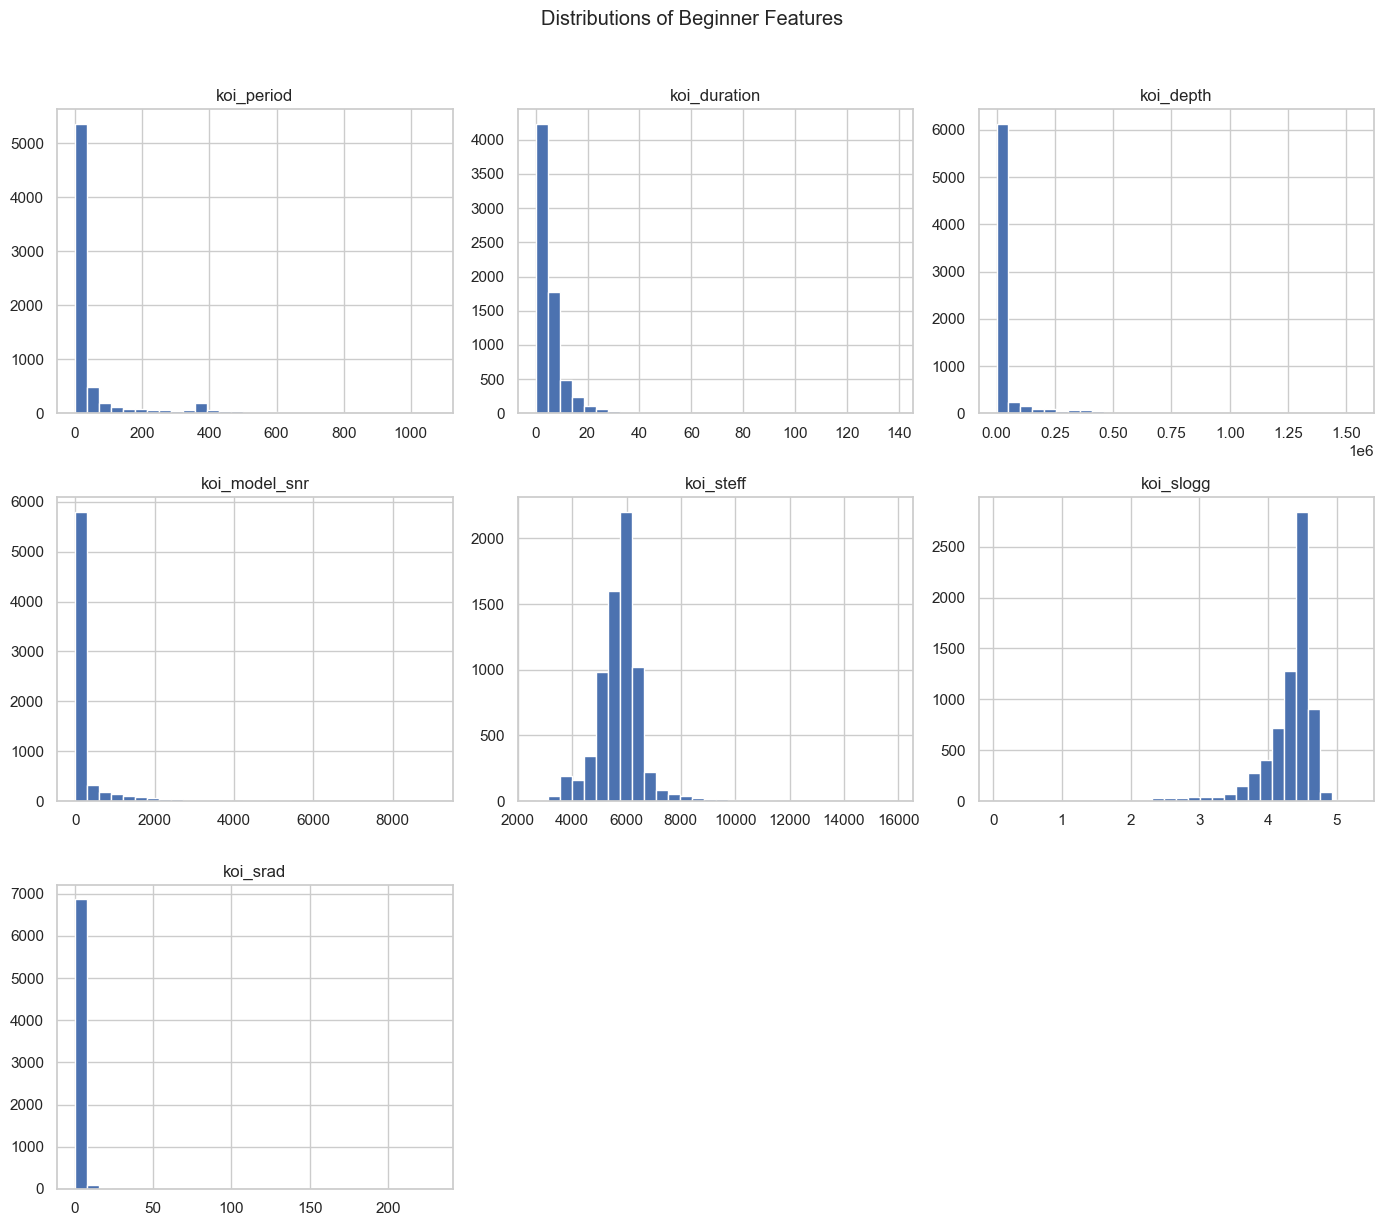

In [19]:
# 6.3 Distributions
df_clean[features].hist(bins=30, figsize=(14, 12))
plt.suptitle("Distributions of Beginner Features", y=1.02)
plt.tight_layout()
plt.show()


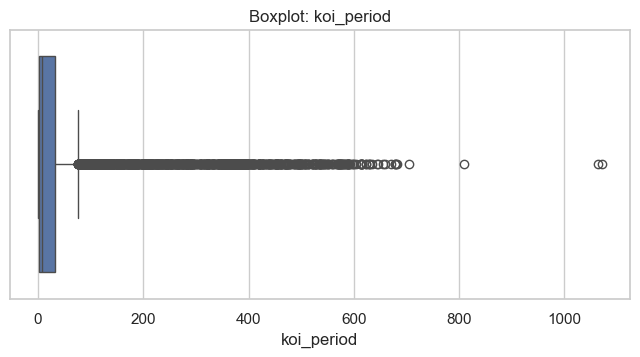

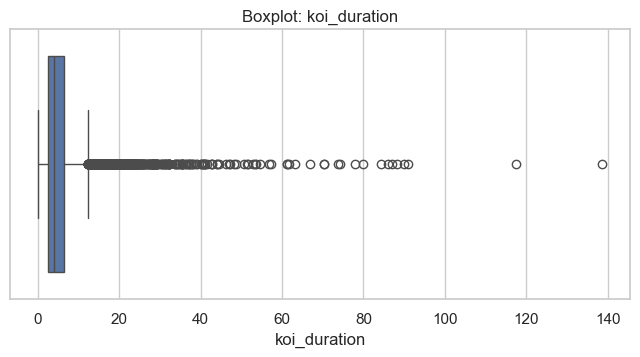

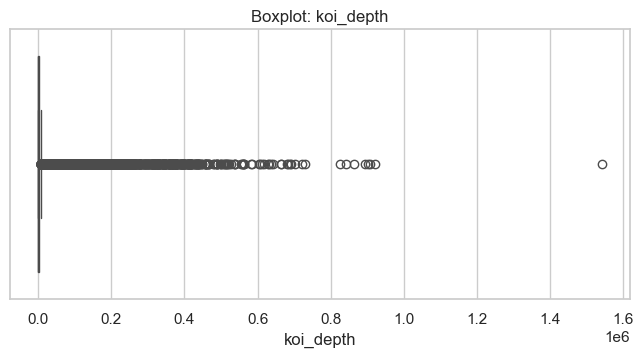

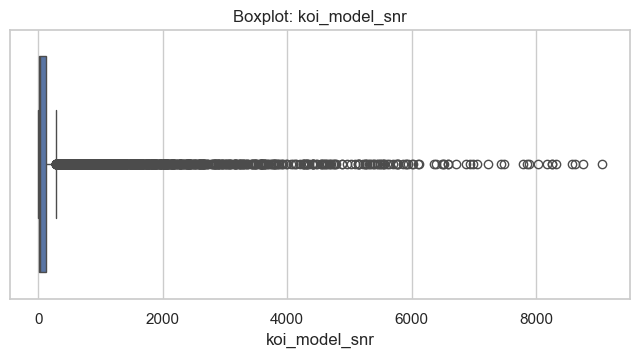

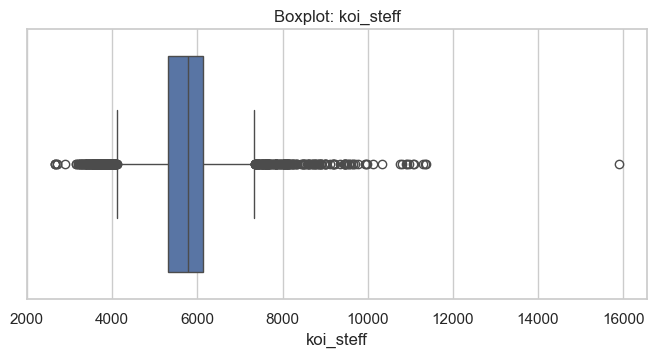

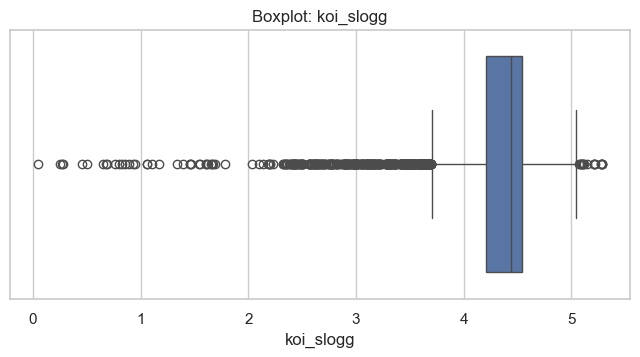

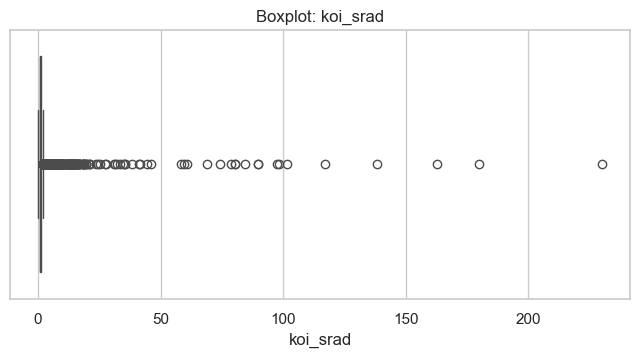

In [21]:
# 6.4 Outlier check using boxplots
for feature in features:
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(x=df_clean[feature])
    plt.title(f"Boxplot: {feature}")
    plt.show()


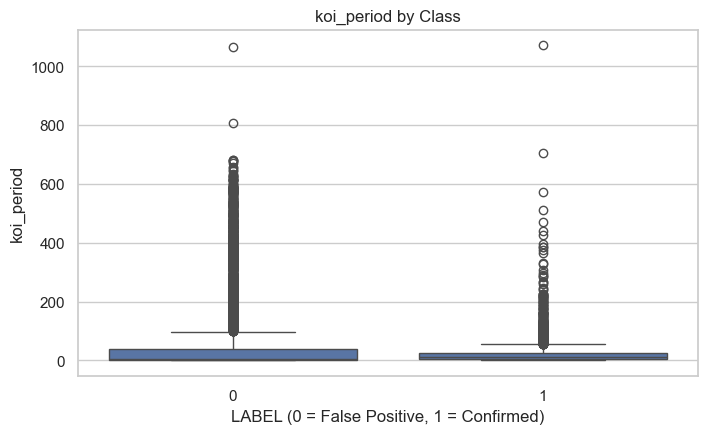

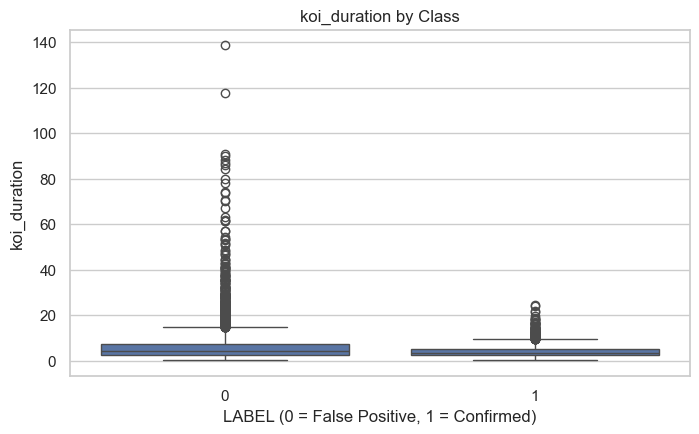

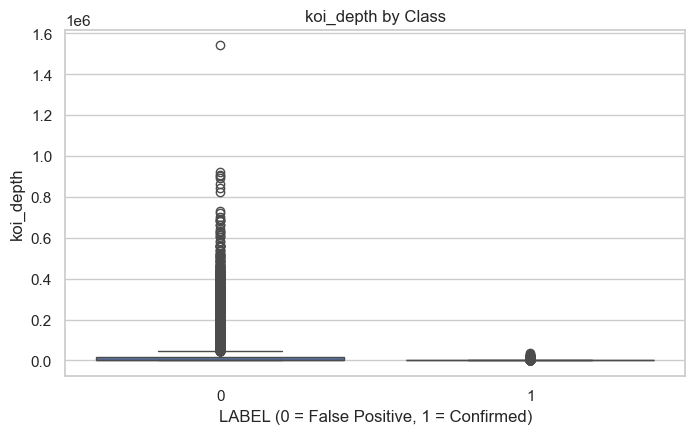

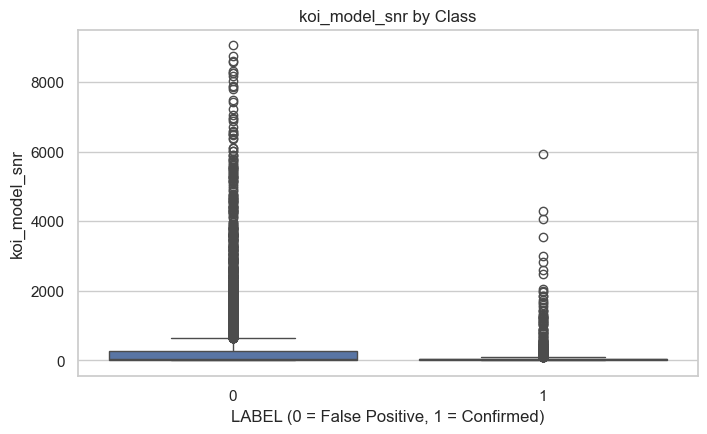

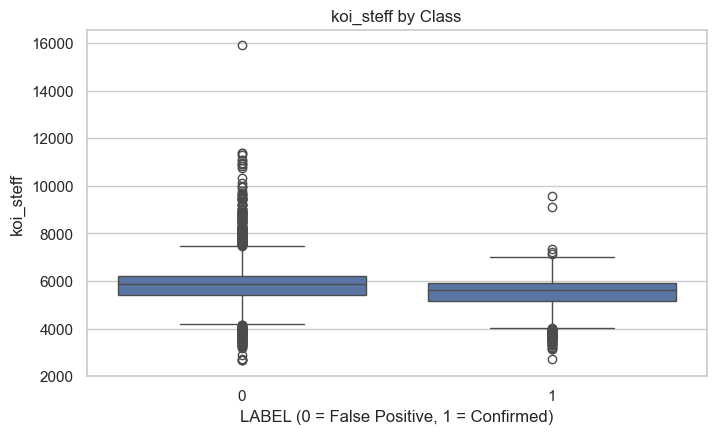

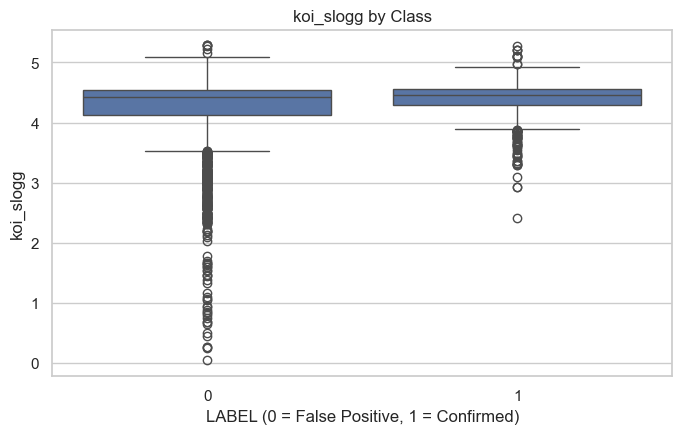

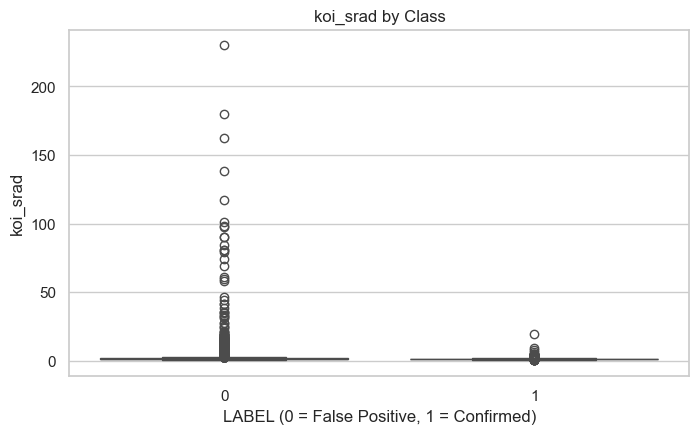

In [23]:
# 6.5 Feature vs target
for feature in features:
    plt.figure(figsize=(8, 4.5))
    sns.boxplot(data=df_clean, x="LABEL", y=feature)
    plt.title(f"{feature} by Class")
    plt.xlabel("LABEL (0 = False Positive, 1 = Confirmed)")
    plt.show()


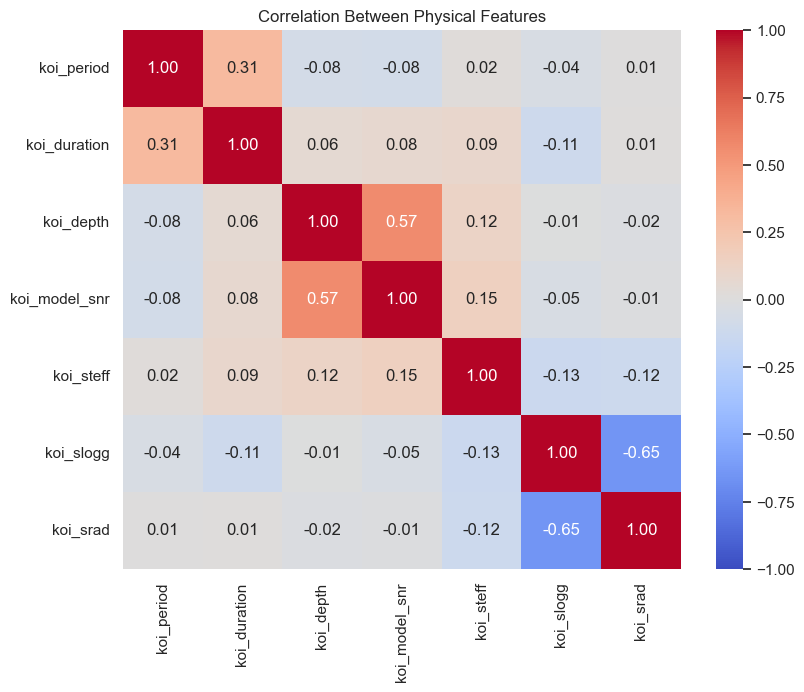

In [25]:
# 6.6 Correlation heatmap
corr = df_clean[features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Correlation Between Physical Features")
plt.show()


### EDA checkpoint

Before moving on, write 3–5 observations in your own words.

For example:

- Which class is more common?
- Which feature is highly skewed?
- Which features appear strongly correlated?
- Which feature seems to separate the classes most clearly?
- Are there extreme values that may need investigation?

**Do not just write what the plot shows. Explain why it might happen physically.**


# 7. Physics-Based Feature Engineering

This is our first real feature-engineering step.

### Feature 1: Transit depth as a fraction

`koi_depth` is measured in parts per million (ppm).

So:

\[
\text{depth fraction} = \frac{\text{koi_depth}}{10^6}
\]

and

\[
\text{depth percent} = \frac{\text{koi_depth}}{10^4}
\]

This makes the physical meaning easier to interpret.

### Feature 2: Fraction of the orbital period spent in transit

The period is in days and the duration is in hours, so:

\[
f_{transit}
=
\frac{\text{duration (hours)}}{24\times\text{period (days)}}
\]

This is dimensionless and expresses how much of one orbit the transit occupies.

### Feature 3: Log-transformed period and SNR

Astronomical measurements can be strongly right-skewed. We use:

\[
\log(1+x)
\]

to compress extreme values while preserving zero-valued observations.


In [28]:
df_model = df_clean.copy()

df_model["transit_depth_fraction"] = df_model["koi_depth"] / 1_000_000
df_model["transit_depth_percent"] = df_model["koi_depth"] / 10_000

df_model["transit_period_fraction"] = (
    df_model["koi_duration"] / (24 * df_model["koi_period"])
)

df_model["log_period"] = np.log1p(df_model["koi_period"])
df_model["log_model_snr"] = np.log1p(df_model["koi_model_snr"])

engineered_features = features + [
    "transit_depth_fraction",
    "transit_depth_percent",
    "transit_period_fraction",
    "log_period",
    "log_model_snr"
]

display(
    df_model[
        ["koi_depth", "transit_depth_fraction", "transit_depth_percent",
         "koi_period", "koi_duration", "transit_period_fraction",
         "log_period", "koi_model_snr", "log_model_snr"]
    ].head()
)


,koi_depth,transit_depth_fraction,transit_depth_percent,koi_period,koi_duration,transit_period_fraction,log_period,koi_model_snr,log_model_snr
0,615.8,0.000616,0.06158,9.488036,2.95750,0.012988,2.350235,35.8,3.605498
1,874.8,0.000875,0.08748,54.418383,4.50700,0.003451,4.014911,25.8,3.288402
2,10829.0,0.010829,1.08290,19.899140,1.78220,0.003732,3.039708,76.3,4.347694
3,8079.2,0.008079,0.80792,1.736952,2.40641,0.057726,1.006845,505.6,6.227722
4,603.3,0.000603,0.06033,2.525592,1.65450,0.027296,1.260048,40.9,3.735286


## 8. Train/Test Split

We keep **20% completely unseen test data**.

The `stratify=y` argument preserves approximately the same class proportions in both sets.

### Why split before scaling?

Because the scaler must learn the mean and standard deviation **only from the training set**.

Otherwise, information from the test set leaks into preprocessing.


In [30]:
X = df_model[engineered_features].copy()
y = df_model["LABEL"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class distribution:")
display(y_train.value_counts(normalize=True).rename(index={0: "FALSE POSITIVE", 1: "CONFIRMED"}))

print("\nTest class distribution:")
display(y_test.value_counts(normalize=True).rename(index={0: "FALSE POSITIVE", 1: "CONFIRMED"}))


Training set: (5612, 12)
Test set: (1404, 12)

Training class distribution:


LABEL
FALSE POSITIVE    0.673378
CONFIRMED         0.326622
Name: proportion, dtype: float64


Test class distribution:


LABEL
FALSE POSITIVE    0.673077
CONFIRMED         0.326923
Name: proportion, dtype: float64

# 9. Baseline Model

Before using ML, we need a benchmark.

A simple baseline predicts the **majority class in the training data for every test example**.

A model is only useful if it beats this trivial strategy.


In [32]:
majority_class = y_train.mode()[0]
baseline_pred = np.full(len(y_test), majority_class)

print("Majority class:", "CONFIRMED" if majority_class == 1 else "FALSE POSITIVE")
print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Baseline balanced accuracy:", round(
    balanced_accuracy_score(y_test, baseline_pred), 4
))


Majority class: FALSE POSITIVE
Baseline accuracy: 0.6731
Baseline balanced accuracy: 0.5


# 10. Scaling

Logistic Regression is sensitive to feature scale.

For example:

- stellar temperature is in thousands of K;
- transit depth is in ppm;
- orbital period is measured in days.

`StandardScaler` transforms each feature approximately to:

\[
z = \frac{x-\mu}{\sigma}
\]

The scaler is fitted only on the training data.


In [34]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled test data shape:", X_test_scaled.shape)


Scaled training data shape: (5612, 12)
Scaled test data shape: (1404, 12)


# 11. ML Model — Logistic Regression

We start with Logistic Regression because it is:

- simple;
- fast;
- a strong baseline for binary classification;
- easy to interpret;
- useful for understanding feature coefficients and probabilities.



In [37]:
model = LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=1000
)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]


# 12. Model Evaluation

For this problem, do not rely on accuracy alone.

We will inspect:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix
- ROC Curve

The confusion matrix is especially useful because it shows exactly how many confirmed objects and false positives were classified correctly or incorrectly.


In [39]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

metrics_df = pd.Series(metrics, name="Score").to_frame()
display(metrics_df)

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["FALSE POSITIVE", "CONFIRMED"],
        zero_division=0
    )
)


,Score
Accuracy,0.832621
Balanced Accuracy,0.823000
Precision,0.721344
Recall,0.795207
F1,0.756477
ROC-AUC,0.913154


Classification Report:
                precision    recall  f1-score   support

FALSE POSITIVE       0.90      0.85      0.87       945
     CONFIRMED       0.72      0.80      0.76       459

      accuracy                           0.83      1404
     macro avg       0.81      0.82      0.81      1404
  weighted avg       0.84      0.83      0.83      1404



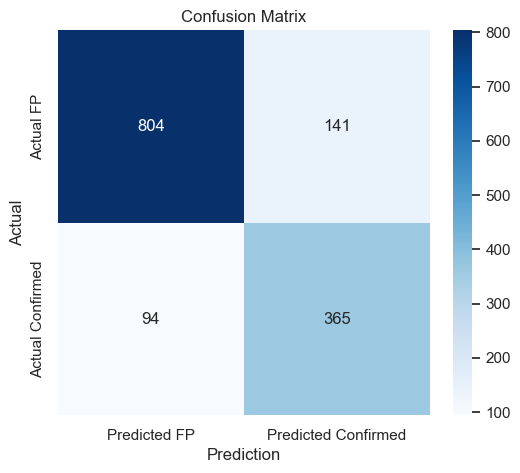

In [41]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted FP", "Predicted Confirmed"],
    yticklabels=["Actual FP", "Actual Confirmed"]
)
plt.title("Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.show()


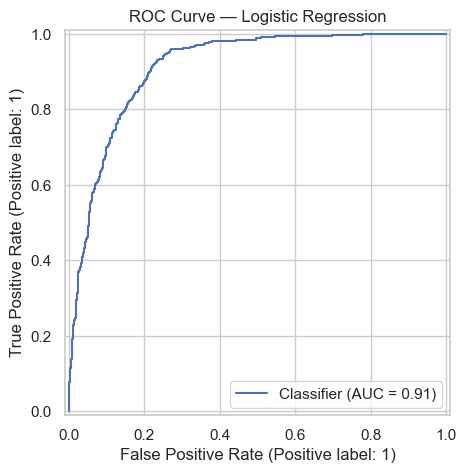

In [43]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve — Logistic Regression")
plt.show()


# 13. Basic Physics Interpretability

Because the features were standardized, the Logistic Regression coefficients can be compared by magnitude.

- Positive coefficient → pushes prediction toward `CONFIRMED`.
- Negative coefficient → pushes prediction toward `FALSE POSITIVE`.
- Larger absolute magnitude → stronger model influence, **within this standardized model**.

Be careful with causal language: a large coefficient does **not** automatically mean that the feature physically causes a planet to exist.


,Feature,Coefficient,Absolute_Coefficient
8,transit_depth_percent,-6.042355,6.042355
2,koi_depth,-6.042355,6.042355
7,transit_depth_fraction,-6.042355,6.042355
6,koi_srad,-3.934109,3.934109
9,transit_period_fraction,-3.240077,3.240077
11,log_model_snr,1.426873,1.426873
0,koi_period,-1.183301,1.183301
4,koi_steff,-0.523572,0.523572
5,koi_slogg,-0.473607,0.473607
3,koi_model_snr,-0.319197,0.319197


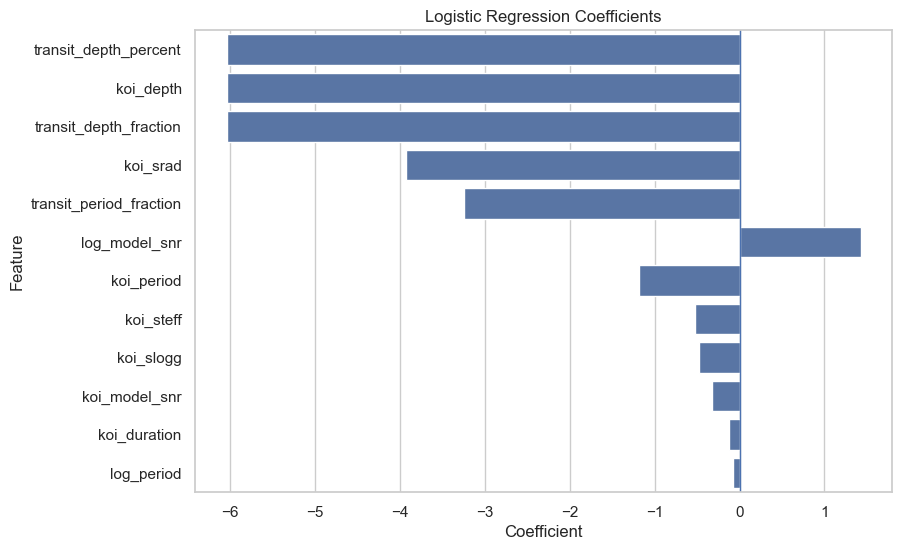

In [45]:
coef_df = pd.DataFrame({
    "Feature": engineered_features,
    "Coefficient": model.coef_[0]
})

coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Absolute_Coefficient", ascending=False)

display(coef_df)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=coef_df,
    x="Coefficient",
    y="Feature"
)
plt.axvline(0, linewidth=1)
plt.title("Logistic Regression Coefficients")
plt.show()
